### 🌾**Deep Learning for Well-watered & Drought Stress Maize Images**

**2D CNN with YOLOv8 Preprocessing**

Input Images Source: https://zenodo.org/records/10991581


Description:
- 2D CNN custom trained CNN model for maize images water stress classification (i.e., Drought vs Watered)
- Roboflow is used to annotate maize ROIs in 50 images & export *.yaml file for generating optimzed YOLOv8 model
- Optimized YOLO model is saved as "best.pt"
- This algorithm use "best.pt" to detect ROIs in all images, and output all ROIs as images for 2D CNN model
- For model construction, augmentation using horizontal flip and zoom are used due to variations in input images sizes
- 2D CNN model is developed with 3 convolutional layers equiped wtih ReLu activation, 64 units dense layer, followed by dropout layer and final dense layer
- The model is compiled using Adam optimizer with learning rate of 1e-3 using Binary Cross Entropy loss
- Model fitting is performed with early stopping & reduce learning rate on plateau, up to maximum 30 epochs

---


Other Resources:
1. TensorFlow Autotuning
https://www.tensorflow.org/guide/data_performance

In [1]:
import pandas as pd
import cv2
from ultralytics import YOLO
from PIL import Image
import json
import os
import numpy as np
from pathlib import Path
import seaborn as sns
import time
import math

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras import regularizers
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense, Dropout, 
                                    RandomFlip, GlobalAveragePooling2D, RandomZoom, Activation, Input, Resizing)
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# from google.colab import drive
from pathlib import Path

SEED_SIZE = 42

# Restart Keras session to clear previous instances
keras.backend.clear_session()

# Set random seed to reproduce same sequence across different runs
keras.utils.set_random_seed(SEED_SIZE)

# Initialize Seaborn theme
sns.set_theme(style='darkgrid')

plt.rcParams.update({
    'font.family': 'monospace',
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8
})


In [2]:
"""---------------------------------
Connect to Google Drive (i.e., Datasets) -- Only use if using Google Colab
------------------------------------"""

# drive.mount('/content/drive')
# DATA_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/DL_assignment/maize_watered_drought_sorted")

'---------------------------------\nConnect to Google Drive (i.e., Datasets) -- Only use if using Google Colab\n------------------------------------'

In [3]:
"""---------------------------------
Connect to Folder Path Containing Train, Test & Validation Images
------------------------------------"""
DATA_ROOT = Path("maize_watered_drought_sorted")

In [4]:
"""---------------------------------
Use trained YOLO Model for Maize ROIs Detection -> Save Cropped ROIs
------------------------------------"""

CROPPED_ROOT = Path("cropped_dataset")

CLASSES = ['Drought_Trial001_2', 'Watered_Trial001_1']
SPLITS = ['train', 'validation', 'test']
yolo_model = YOLO("best.pt")

def extract_and_save_rois():

    # Check if folder to store cropped ROIs already exist
    if CROPPED_ROOT.exists():
        print("Cropped ROIs folder exist, continue...")
        return

    for split in SPLITS:
        for class_name in CLASSES:
            input_dir = DATA_ROOT / split / class_name
            output_dir = CROPPED_ROOT / split / class_name
            output_dir.mkdir(parents=True, exist_ok=True)
            
            if not input_dir.exists():
                continue
                
            for img_name in os.listdir(input_dir):
                img_path = input_dir / img_name
                img = cv2.imread(str(img_path))
                if img is None:
                    continue
                
                # Use trained YOLO model to detect ROIs for maize
                results = yolo_model(img, conf=0.3, iou=0.4, verbose=False)
                
                box_count = 0 # Initialize bounding box count in image
                for result in results:
                    for box in result.boxes:
                        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                        
                        # Cropping image based on output ROIs
                        roi = img[y1:y2, x1:x2]

                        # Set threshold to exclude tiny ROIs (potentially not useful)
                        if roi.size > 0 and (x2 - x1) > 20 and (y2 - y1) > 20: 
                            box_count += 1

                            # Save ROI as image file
                            save_path = output_dir / f"{Path(img_name).stem}_crop{box_count}.jpg"
                            cv2.imwrite(str(save_path), roi)
                
                # For image with zero ROI, to output same image
                if box_count == 0:
                    fallback_path = output_dir / img_name
                    cv2.imwrite(str(fallback_path), img)

# Execute ROIs extraction & saving
# extract_and_save_rois() # commented for training after completed once...

Max Width:  1640 | Max Height: 1232
Ave Width:  727  | Ave Height: 428
Med Width:  685  | Med Height: 432


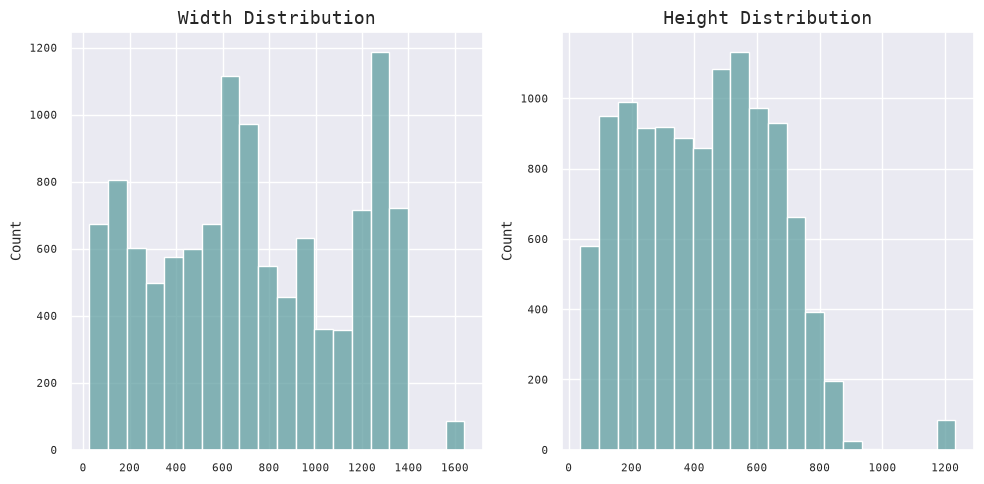

In [5]:
"""---------------------------------
Analysis for Input Images Based on ROIs Generated from YOLO Detection
------------------------------------"""


def analyze_image_sizes(dataset_dir):
    width = []
    height = []
    extension = {".jpg"}
    
    # Loop through all images...
    for img_path in Path(dataset_dir).rglob("*"):
        if img_path.suffix.lower() in extension:

            # Obtain width/height information
            with Image.open(img_path) as img:
                w, h = img.size
                width.append(w)
                height.append(h)

    # Compute mean, max and median width and height
    print(f"Max Width:  {max(width)} | Max Height: {max(height)}")
    print(f"Ave Width:  {int(sum(width)/len(width))}  | Ave Height: {int(sum(height)/len(height))}")
    print(f"Med Width:  {int(np.median(width))}  | Med Height: {int(np.median(height))}")

    # Generate historgram plot for width & height distributions
    fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10,5))

    sns.histplot(width, bins=20, color='cadetblue', ax=ax[0])
    ax[0].set_title('Width Distribution', fontsize=13)
    ax[0].grid(True)

    sns.histplot(height, bins=20, color='cadetblue', ax=ax[1])
    ax[1].set_title('Height Distribution', fontsize=13)
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()

analyze_image_sizes('./cropped_dataset')

In [6]:
"""---------------------------------
Load train-test-val data sets
------------------------------------"""

BATCH_SIZE = 64
# IMAGE_SIZE = (432, 685)
IMAGE_SIZE = (224, 224)
CLASSES = ['Drought_Trial001_2', 'Watered_Trial001_1']
DATA_ROOT_CROPPED = Path('./cropped_dataset')


train_ds = keras.utils.image_dataset_from_directory(
    DATA_ROOT_CROPPED / "train",
    image_size=IMAGE_SIZE,
    pad_to_aspect_ratio=True,
    batch_size=None,
    label_mode="binary",
    class_names=CLASSES,
    shuffle=True,
    seed=SEED_SIZE
)

validation_ds = keras.utils.image_dataset_from_directory(
    DATA_ROOT_CROPPED / "validation",
    image_size=IMAGE_SIZE,
    pad_to_aspect_ratio=True,
    batch_size=None,
    label_mode="binary",
    class_names=CLASSES,
    shuffle=False,

)

test_ds = keras.utils.image_dataset_from_directory(
    DATA_ROOT_CROPPED / "test",
    image_size=IMAGE_SIZE,
    pad_to_aspect_ratio=True,
    batch_size=None,
    label_mode="binary",
    class_names=CLASSES,
    shuffle=False
)


Found 8069 files belonging to 2 classes.
Found 1757 files belonging to 2 classes.
Found 1745 files belonging to 2 classes.


In [7]:
"""---------------------------------
Dataset Normalization & Optimization of TensorFlow Pipeline
------------------------------------"""

AUTOTUNE = tf.data.AUTOTUNE

def resize_with_padding(image, label):
    image = tf.image.resize_with_pad(image, target_height=224, target_width=224)
    image.set_shape([224, 224, 3]) 
    return image, label

validation_ds = validation_ds.map(resize_with_padding, num_parallel_calls=AUTOTUNE)
validation_ds = validation_ds.batch(BATCH_SIZE)
validation_ds = validation_ds.prefetch(buffer_size=AUTOTUNE)

test_ds = test_ds.map(resize_with_padding, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)


train_ds = train_ds.map(resize_with_padding, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.shuffle(2000, seed=SEED_SIZE)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)


In [8]:
"""---------------------------------
Model 3 - CNN (post YOLO preprocessing)
------------------------------------"""
trainingtime_start = time.perf_counter() # Start time counter

FILTER_1 = 32
FILTER_2 = 64
FILTER_3 = 128
KERNEL_SIZE = (3,3)

tf.keras.backend.clear_session()

CNN_model = Sequential([
    Input(shape=(None, None, 3)),
    Resizing(IMAGE_SIZE[0], IMAGE_SIZE[1], crop_to_aspect_ratio=True),
    
    RandomFlip("horizontal"), 
    RandomZoom(0.1),

    Conv2D(FILTER_1, KERNEL_SIZE, padding = 'same'),
    Activation('relu'),
    MaxPooling2D(2, 2),
    

    Conv2D(FILTER_2, KERNEL_SIZE, padding = 'same'),
    Activation('relu'),
    MaxPooling2D(2, 2),

    Conv2D(FILTER_3, KERNEL_SIZE, padding = 'same'),
    Activation('relu'),
    MaxPooling2D(2, 2),
    
    GlobalAveragePooling2D(),
    Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.4),
    Dense(1, activation='sigmoid', dtype='float32',  kernel_initializer='glorot_uniform') #kernel_initializer='he_normal'

], name='CNN_classifier')

In [9]:
"""---------------------------------
Model Fitting
------------------------------------"""

CNN_model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss = 'binary_crossentropy', 
    metrics = ['accuracy', 'precision', 'recall', 'auc']
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=5,          
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1)


CNN_history = CNN_model.fit(train_ds,
              validation_data = validation_ds,
              epochs = 30,
              callbacks=[early_stopping, reduce_lr])

# print(CNN_history.history)

# Compute training time
trainingtime_end = time.perf_counter()
training_duration = trainingtime_end - trainingtime_start

print(f"Training Time: {training_duration:.4f} seconds")

Epoch 1/30


c:\Users\ptong\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


127/127 ━━━━━━━━━━━━━━━━━━━━ 59s 444ms/step - accuracy: 0.5133 - auc: 0.5172 - loss: 0.8789 - precision: 0.5203 - recall: 0.4634 - val_accuracy: 0.5418 - val_auc: 0.5422 - val_loss: 0.6974 - val_precision: 0.5255 - val_recall: 0.8554 - learning_rate: 0.0010
Epoch 2/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 59s 457ms/step - accuracy: 0.5463 - auc: 0.5608 - loss: 0.6942 - precision: 0.5472 - recall: 0.5876 - val_accuracy: 0.5737 - val_auc: 0.6048 - val_loss: 0.6900 - val_precision: 0.5586 - val_recall: 0.7005 - learning_rate: 0.0010
Epoch 3/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 60s 471ms/step - accuracy: 0.5481 - auc: 0.5642 - loss: 0.6926 - precision: 0.5550 - recall: 0.5302 - val_accuracy: 0.5965 - val_auc: 0.6106 - val_loss: 0.6827 - val_precision: 0.5894 - val_recall: 0.6344 - learning_rate: 0.0010
Epoch 4/30
127/127 ━━━━━━━━━━━━━━━━━━━━ 60s 471ms/step - accuracy: 0.5649 - auc: 0.5858 - loss: 0.6871 - precision: 0.5739 - recall: 0.5366 - val_accuracy: 0.5481 - val_auc: 0.6219 - val_loss: 0.6893 - va

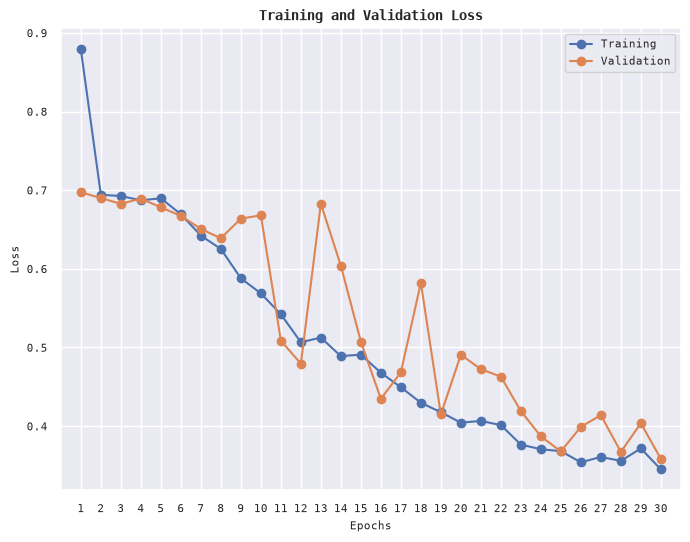

In [10]:
"""---------------------------------
Generating Epochs vs Error Plot
------------------------------------"""

x_data = list(range(1, 31))
plt.figure(figsize=(8,6))
plt.plot(x_data, CNN_history.history['loss'], label='Training', marker='o')
plt.plot(x_data, CNN_history.history['val_loss'], label='Validation', marker='o')

plt.xlim(0, 31)
plt.xticks(range(1, 31))
plt.xlabel('Epochs', fontsize=8)
plt.ylabel('Loss', fontsize=8)
plt.grid(True, linestyle='-', linewidth=1)
plt.title('Training and Validation Loss', fontsize=10, fontweight='bold')
plt.legend(fontsize=8)
plt.show()

Accuracy: 0.8315
precision: 0.8992
recall: 0.75
f1: 0.8178
Confusion Matrix:
[[791  74]
 [220 660]]


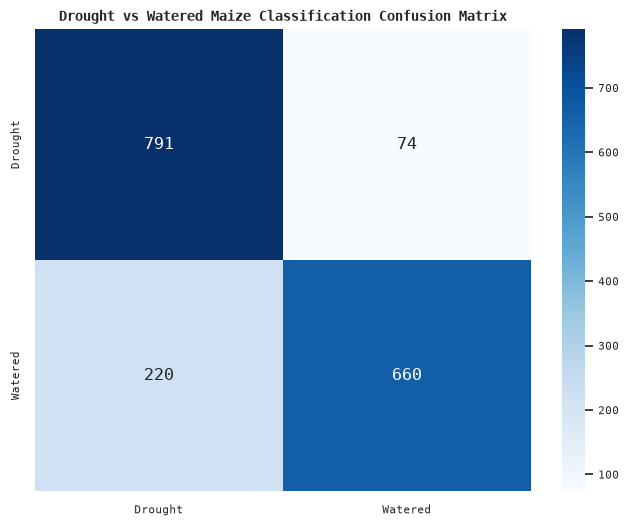

In [11]:
"""---------------------------------
Summary Results
------------------------------------"""

test_ypred_raw = CNN_model.predict(test_ds, verbose=0).flatten()
test_ytrue = np.concatenate([y.numpy() for _, y in test_ds], axis=0).flatten().astype(int)
test_ypred = (test_ypred_raw >= 0.5).astype(int)

# Extract ground truth labels & convert to 1D numpy array of intergers
test_conmat = confusion_matrix(test_ytrue, test_ypred)

# Compute for accuracy, precision, recall and F1 score
accuracy = accuracy_score(test_ytrue, test_ypred)
precision = precision_score(test_ytrue, test_ypred, zero_division=0)
recall = recall_score(test_ytrue, test_ypred, zero_division=0)
f1 = f1_score(test_ytrue, test_ypred, zero_division=0)

print(f'Accuracy: {round((accuracy),4)}')
print(f'precision: {round((precision),4)}')
print(f'recall: {round((recall),4)}')
print(f'f1: {round((f1),4)}')
print(f'Confusion Matrix:\n{test_conmat}')

# Define class names for Confusion Matrix
class_names = ['Drought', 'Watered'] 

# Generate Confusion Matrix Chart
plt.figure(figsize=(8, 6))
sns.heatmap(test_conmat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Drought vs Watered Maize Classification Confusion Matrix", fontsize=10, fontweight='bold')
plt.show()

In [12]:
CNN_model.summary()

Model: "CNN_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,709 (1.16 MB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,140 (793.52 KB)